In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv


In [2]:
# ==========================================
# Phase 1: Import Libraries and Load Dataset
# Objective: Load the dataset and prepare the environment
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)

df = pd.read_csv(
    '/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv',
    sep=';'
)

df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)
print("Dataset Loaded Successfully!")

Dataset Shape: (4424, 37)
Dataset Loaded Successfully!


In [3]:
# Separate features and target
X = df.drop(columns=['Target'])
y = df['Target']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("\nTarget Classes:")
print(y.value_counts())

Features Shape: (4424, 36)
Target Shape: (4424,)

Target Classes:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [4]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (3539, 36)
Testing Features: (885, 36)
Training Target: (3539,)
Testing Target: (885,)


In [5]:
# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [6]:
# Make predictions
y_pred = rf_model.predict(X_test)

print("Predictions Completed Successfully!")
print("\nFirst 10 Predictions:")
print(y_pred[:10])

Predictions Completed Successfully!

First 10 Predictions:
['Graduate' 'Graduate' 'Dropout' 'Graduate' 'Graduate' 'Graduate'
 'Graduate' 'Graduate' 'Graduate' 'Graduate']


In [7]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')

print("Random Forest Baseline Results")
print("------------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

Random Forest Baseline Results
------------------------------
Accuracy: 0.7672
Precision: 0.7214
Recall: 0.6802
F1-Score: 0.6916


In [8]:
# Display classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     Dropout       0.81      0.75      0.78       284
    Enrolled       0.57      0.37      0.45       159
    Graduate       0.78      0.92      0.85       442

    accuracy                           0.77       885
   macro avg       0.72      0.68      0.69       885
weighted avg       0.75      0.77      0.75       885



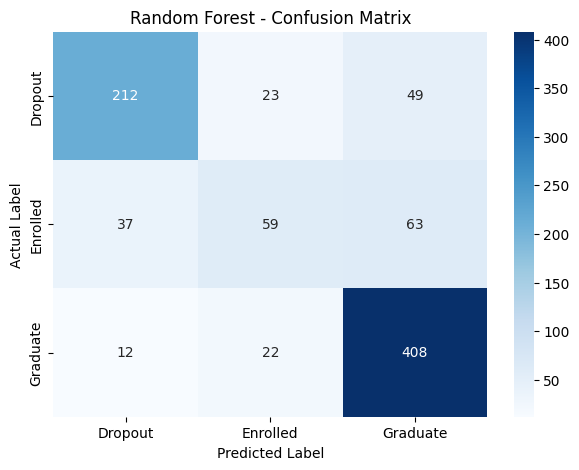

In [9]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [10]:
# Calculate feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 10 features
print(feature_importance.head(10))

                                   Feature  Importance
30     Curricular units 2nd sem (approved)    0.142283
31        Curricular units 2nd sem (grade)    0.109008
24     Curricular units 1st sem (approved)    0.091937
25        Curricular units 1st sem (grade)    0.059588
12                         Admission grade    0.043575
19                       Age at enrollment    0.040287
16                 Tuition fees up to date    0.038903
29  Curricular units 2nd sem (evaluations)    0.038200
23  Curricular units 1st sem (evaluations)    0.037504
6           Previous qualification (grade)    0.037498


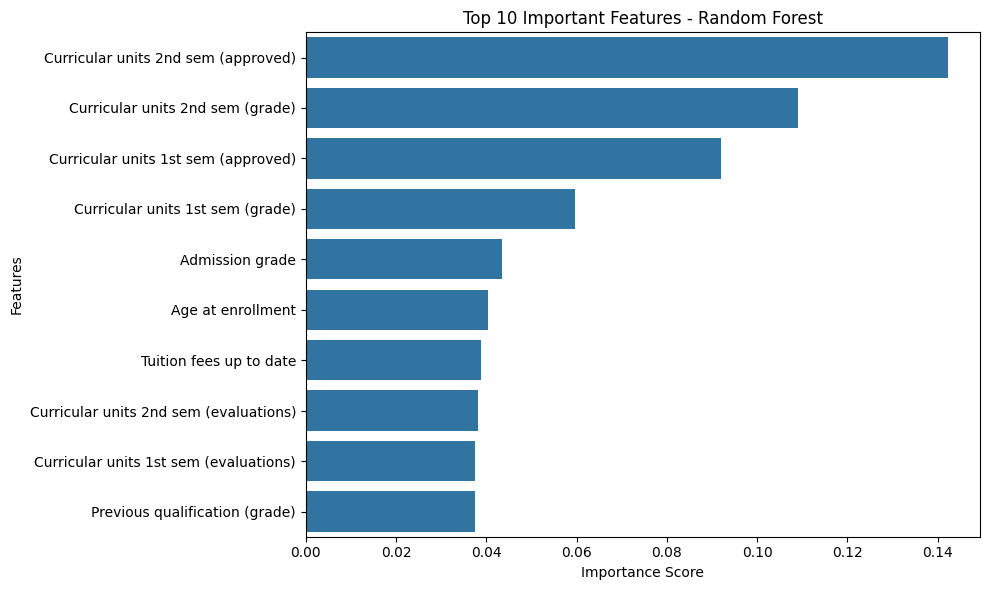

In [11]:
# Plot top 10 important features
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [12]:
# Store baseline results
baseline_results = {
    'Model': 'Random Forest Baseline',
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1
}

baseline_results_df = pd.DataFrame([baseline_results])

print(baseline_results_df)

                    Model  Accuracy  Precision    Recall  F1-Score
0  Random Forest Baseline  0.767232   0.721395  0.680208  0.691628
